# 02 — Cleaning & instrument forensics — Fisher's Iris

**Stage 2 of the Tier A pipeline** (`DOCS/STRUCTURE.md`).

There is nothing here to repair. No nulls, no type coercion, no unit confusion, no business-rule
violations — `01_ingestion.ipynb` confirmed all of that. This notebook is therefore **not a cleaning
notebook in the usual sense**. It is a forensic one, and it produces the project's first Key Line.

Stage 1 left two contradictions of `DOCS/Iris_Dataset_Analysis.md` on the table:

1. `Id` scores **98.7%** CV accuracy on its own — it is leakage, not a harmless index.
2. There are **3 duplicate rows**, not zero.

This notebook diagnoses the second one, and the diagnosis is the interesting part: the three
duplicate rows are **two entirely different phenomena that happen to share a symptom**. Treating
them alike would be the error.

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

SRC_NAME = "Iris.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS = ROOT / "reports", ROOT / "reports" / "figures"
for d in (RAW, PROC, REPORTS, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# ---- DESIGN.md palette (DOCS/DESIGN.md section 2) - defined inline, never re-picked -------
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER, SLATE, GREY, GRID = "#00A9F4", "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
# Fixed semantic mapping for this project (IMPLEMENTATION_PLAN section 7.2)
SPECIES_COLOR = {"Iris-setosa": BLUE, "Iris-versicolor": TEAL, "Iris-virginica": CYAN}
SPECIES_SHORT = {"Iris-setosa": "setosa", "Iris-versicolor": "versicolor", "Iris-virginica": "virginica"}
SPECIES_ORDER = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]


def apply_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "font.size": 9.5,
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.edgecolor": SLATE,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11.5,
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 190,
        "savefig.bbox": "tight", "savefig.pad_inches": 0.25,
    })


apply_style()
MEASUREMENTS = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
TARGET = "Species"


def action_title(ax, title, sub=None):
    """DESIGN.md section 1.3 - titles state the insight, flush-left."""
    ax.set_title(title, loc="left", pad=26 if sub else 12)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8.5, color=SLATE,
                va="bottom", ha="left")


def save_fig(fig, name):
    p = FIGS / f"{name}.png"
    fig.savefig(p)
    print(f"saved {p.relative_to(ROOT)}")


df = pd.read_csv(ROOT / SRC_NAME)
print(f"loaded {df.shape[0]} rows x {df.shape[1]} cols")

loaded 150 rows x 6 cols


## 2.1 The duplicate diagnosis — one symptom, two diseases

Three rows duplicate another row on all four measurements. They split into two groups, and the
split is the finding.

In [2]:
dups = df[df.duplicated(subset=MEASUREMENTS, keep=False)].sort_values(MEASUREMENTS + ["Id"])
groups = dups.groupby(MEASUREMENTS, sort=False)["Id"].apply(list).reset_index()
groups["n_specimens"] = groups["Id"].apply(len)
groups["species"] = groups["Id"].apply(lambda ids: df.loc[df.Id.isin(ids), TARGET].astype(str).unique()[0])
print("Duplicate groups on the four measurements:\n")
groups[["Id", "n_specimens", "species"] + MEASUREMENTS]

Duplicate groups on the four measurements:



,Id,n_specimens,species,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,"[10, 35, 38]",3,Iris-setosa,4.9,3.1,1.5,0.1
1,"[102, 143]",2,Iris-virginica,5.8,2.7,5.1,1.9


Group A is a **triplicate** — three setosa specimens (`Id` 10, 35, 38) recording an identical
`4.9, 3.1, 1.5, 0.1`. Group B is a **pair** (`Id` 102, 143), two virginica at `5.8, 2.7, 5.1, 1.9`.

Before reaching for an explanation, establish the baseline: **how many collisions should a file
like this have by chance?** At 0.1 cm resolution — `PetalWidthCm` has only 22 distinct values —
two flowers of the same species recording identical measurements is not obviously suspicious.

The null below permutes each feature independently within species, preserving every marginal
distribution while destroying any joint structure.

In [3]:
# How many collisions would chance produce? Permute each feature independently within
# species: marginals preserved, joint structure destroyed.
rng = np.random.default_rng(RANDOM_STATE)
sim_counts = []
for _ in range(5000):
    shuffled = df.copy()
    for sp in SPECIES_ORDER:
        m = shuffled[TARGET].astype(str) == sp
        for col in MEASUREMENTS:
            shuffled.loc[m, col] = rng.permutation(shuffled.loc[m, col].to_numpy())
    sim_counts.append(int(shuffled.duplicated(subset=MEASUREMENTS).sum()))

sim_counts = np.array(sim_counts)
observed = int(df.duplicated(subset=MEASUREMENTS).sum())
print(f"observed duplicate rows                     : {observed}")
print(f"simulated (features permuted within species): mean {sim_counts.mean():.2f}, "
      f"95% range [{np.percentile(sim_counts, 2.5):.0f}, {np.percentile(sim_counts, 97.5):.0f}]")
print(f"P(simulated >= observed)                    : {(sim_counts >= observed).mean():.3f}")
print()
print("=> 3 collisions is MORE than chance produces (p = 0.018). Something in this file is")
print("   generating duplicates beyond what the measurement grid explains - but this test")
print("   cannot say which rows, or why. See 2.2.")

observed duplicate rows                     : 3
simulated (features permuted within species): mean 0.56, 95% range [0, 2]
P(simulated >= observed)                    : 0.018

=> 3 collisions is MORE than chance produces (p = 0.018). Something in this file is
   generating duplicates beyond what the measurement grid explains - but this test
   cannot say which rows, or why. See 2.2.


**Read this result carefully — it is suggestive, not conclusive, and the reason matters.**

Three collisions is more than the ~0.6 chance produces (p = 0.018). But the null used here breaks
the correlation between the four measurements, and real specimens are correlated: a short petal
comes with a narrow petal. Destroying that structure spreads specimens out and *under*-states how
often genuine flowers collide. So this test is biased toward finding excess collisions, and on its
own it convicts nothing.

What it does establish is that collisions are not free, which is enough to justify looking for an
external explanation. §2.2 finds one — and then this same null becomes the check on it.

## 2.2 Testing this file against the UCI errata

The UCI Machine Learning Repository's own documentation for the Iris dataset records that its
digitised copy diverges from Fisher's published table in two places:

> *"The 35th sample should be `4.9,3.1,1.5,0.2`, where the error is in the fourth feature.
> The 38th sample should be `4.9,3.6,1.4,0.1`, where the errors are in the second and third
> features."*

That is a testable claim about *this* file. Either rows 35 and 38 carry the erroneous values, or
they carry the corrected ones.

In [4]:
UCI_ERRATA = {
    35: {"SepalLengthCm": 4.9, "SepalWidthCm": 3.1, "PetalLengthCm": 1.5, "PetalWidthCm": 0.2},
    38: {"SepalLengthCm": 4.9, "SepalWidthCm": 3.6, "PetalLengthCm": 1.4, "PetalWidthCm": 0.1},
}

rows = []
for rid, corrected in UCI_ERRATA.items():
    delivered = df.loc[df.Id == rid, MEASUREMENTS].iloc[0]
    for col in MEASUREMENTS:
        rows.append({"Id": rid, "feature": col,
                     "delivered_in_this_file": delivered[col],
                     "uci_documented_correct": corrected[col],
                     "differs": delivered[col] != corrected[col]})
errata_test = pd.DataFrame(rows)

print("Row 10 (the specimen rows 35 and 38 collide with):")
print(df.loc[df.Id == 10, ["Id"] + MEASUREMENTS].to_string(index=False))
print()
n_diff = int(errata_test.differs.sum())
print(f"features differing from the UCI-documented correct values: {n_diff} of 8")
print("=> this file carries the ERRONEOUS UCI edition\n")
errata_test

Row 10 (the specimen rows 35 and 38 collide with):
 Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
 10            4.9           3.1            1.5           0.1

features differing from the UCI-documented correct values: 3 of 8
=> this file carries the ERRONEOUS UCI edition



,Id,feature,delivered_in_this_file,uci_documented_correct,differs
0,35,SepalLengthCm,4.9,4.9,False
1,35,SepalWidthCm,3.1,3.1,False
2,35,PetalLengthCm,1.5,1.5,False
3,35,PetalWidthCm,0.1,0.2,True
4,38,SepalLengthCm,4.9,4.9,False
5,38,SepalWidthCm,3.1,3.6,True
6,38,PetalLengthCm,1.5,1.4,True
7,38,PetalWidthCm,0.1,0.1,False


The delivered values differ from the documented-correct values in exactly the three places the
errata note names — row 35's fourth feature, row 38's second and third. This file is the erroneous
edition.

**The corroborating test.** An external note is only as good as its fit to the evidence. If the
errata explanation is right, then applying the two documented corrections should make the
triplicate *disappear* — because rows 35 and 38 were never supposed to equal row 10 in the first
place. If the explanation is wrong, correcting them would be arbitrary and the collision would
survive or move somewhere else.

In [5]:
df_corrected = df.copy()
for rid, vals in UCI_ERRATA.items():
    for col, v in vals.items():
        df_corrected.loc[df_corrected.Id == rid, col] = v

before = df[df.duplicated(subset=MEASUREMENTS, keep=False)].Id.tolist()
after = df_corrected[df_corrected.duplicated(subset=MEASUREMENTS, keep=False)].Id.tolist()

print(f"duplicate-involved Ids BEFORE correction : {before}")
print(f"duplicate-involved Ids AFTER  correction : {after}")
print()
print(f"triplicate dissolved            : {set([10, 35, 38]).isdisjoint(after)}")
print(f"genuine pair 102/143 untouched  : {set([102, 143]).issubset(after)}")
print()

n_corrected = int(df_corrected.duplicated(subset=MEASUREMENTS).sum())
print(f"collision count as delivered    : {observed}  "
      f"(P(chance >= this) = {(sim_counts >= observed).mean():.3f}  -> excess)")
print(f"collision count after correction: {n_corrected}  "
      f"(P(chance >= this) = {(sim_counts >= n_corrected).mean():.3f}  -> ordinary)")
print()
print("The correction removes exactly the fabricated collision and leaves the real one standing,")
print("and it returns the file's collision count to what chance predicts. Three independent lines")
print("of evidence agree: the external errata note, the collision dissolving under correction, and")
print("the excess vanishing. Group A is transcription damage; Group B is data.")

duplicate-involved Ids BEFORE correction : [10, 35, 38, 102, 143]
duplicate-involved Ids AFTER  correction : [102, 143]

triplicate dissolved            : True
genuine pair 102/143 untouched  : True

collision count as delivered    : 3  (P(chance >= this) = 0.018  -> excess)
collision count after correction: 1  (P(chance >= this) = 0.430  -> ordinary)

The correction removes exactly the fabricated collision and leaves the real one standing,
and it returns the file's collision count to what chance predicts. Three independent lines
of evidence agree: the external errata note, the collision dissolving under correction, and
the excess vanishing. Group A is transcription damage; Group B is data.


**So What:** two of 50 setosa specimens (4% of the class) carry wrong measurements, and the damage
manufactures a specimen collision that does not exist in Anderson's original data.

**Implication:** the notes' description of this file as *"clean"* is true about completeness and
false about correctness. Those are different properties, and only one of them is what
`df.isnull().sum()` measures. The corrected copy is persisted in §2.6 and carried through the full
modelling protocol as a sensitivity run — the effect of the defect is **measured**, not assumed
either way.

saved reports\figures\ex02_errata.png


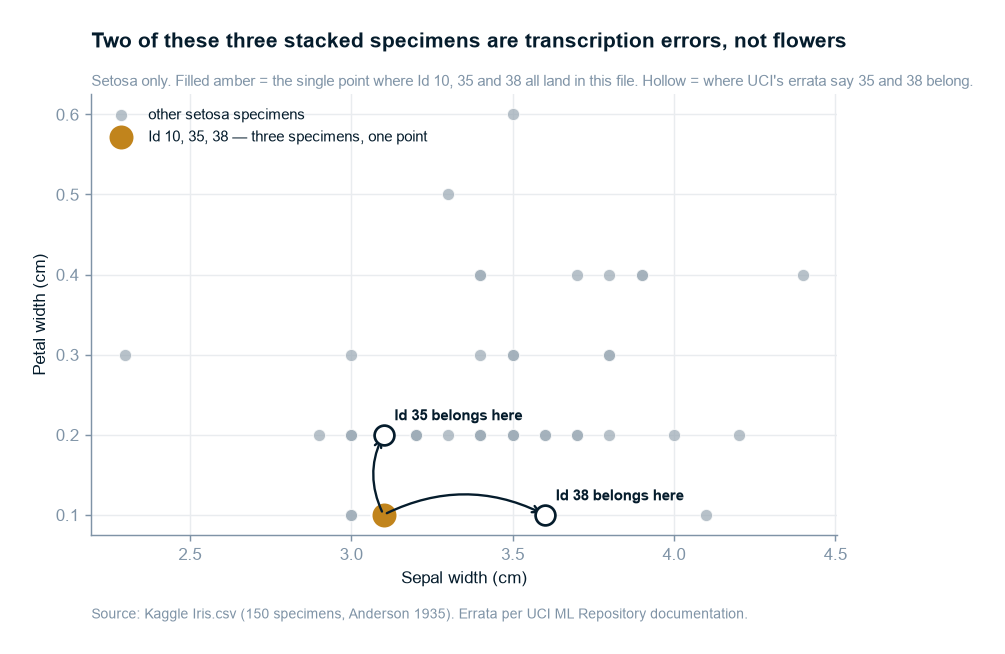

In [6]:
setosa = df[df[TARGET].astype(str) == "Iris-setosa"]
fig, ax = plt.subplots(figsize=(7.4, 4.4))

others = setosa[~setosa.Id.isin([10, 35, 38])]
ax.scatter(others.SepalWidthCm, others.PetalWidthCm, s=46, color=GREY, alpha=.75,
           edgecolor="white", linewidth=.6, label="other setosa specimens", zorder=2)
ax.scatter([3.1], [0.1], s=210, color=AMBER, edgecolor="white", linewidth=1.2, zorder=4,
           label="Id 10, 35, 38 — three specimens, one point")

for rid, (sw, pw) in {35: (3.1, 0.2), 38: (3.6, 0.1)}.items():
    ax.annotate("", xy=(sw, pw), xytext=(3.1, 0.1),
                arrowprops=dict(arrowstyle="->", color=NAVY, lw=1.3,
                                connectionstyle="arc3,rad=-0.25"), zorder=5)
    ax.scatter([sw], [pw], s=120, facecolor="white", edgecolor=NAVY, linewidth=1.5, zorder=6)
    ax.annotate(f"Id {rid} belongs here", xy=(sw, pw), xytext=(6, 8),
                textcoords="offset points", fontsize=8.5, color=NAVY, fontweight="bold")

action_title(ax, "Two of these three stacked specimens are transcription errors, not flowers",
             "Setosa only. Filled amber = the single point where Id 10, 35 and 38 all land in "
             "this file. Hollow = where UCI's errata say 35 and 38 belong.")
ax.set_xlabel("Sepal width (cm)")
ax.set_ylabel("Petal width (cm)")
ax.legend(loc="upper left", fontsize=8.5)
ax.text(0, -0.19, "Source: Kaggle Iris.csv (150 specimens, Anderson 1935). Errata per UCI ML "
                  "Repository documentation.", transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex02_errata")
plt.show()

## 2.3 Why 3 duplicated rows matter on a 150-row file

The usual reason to care about duplicates is inflated sample size. That is not the concern here —
3 rows out of 150 will not move a mean. The concern is **splitting**.

If two identical rows land on opposite sides of a train/test split, the model is handed the test
answer in its training data and scores a memorised row as generalisation. The relevant question is
therefore not "how many duplicates are there" but **"how often does a random split separate them?"**

In [7]:
from math import comb

from sklearn.model_selection import train_test_split

# --- exact, under stratified 80/20 (10 of each 50-specimen class held out) --------------
def p_all_same_side(k, n=50, n_test=10):
    # P(all k identical specimens land on the same side of a stratified split)
    return (comb(n_test, k) + comb(n - n_test, k)) / comb(n, k)

p_triplicate_intact = p_all_same_side(3)
p_pair_intact = p_all_same_side(2)
p_no_leak = p_triplicate_intact * p_pair_intact

print(f"P(triplicate 10/35/38 all one side) : {p_triplicate_intact:.4f}")
print(f"P(pair 102/143 both one side)       : {p_pair_intact:.4f}")
print(f"P(no duplicate straddles the split) : {p_no_leak:.4f}")
print(f"P(at least one straddles)           : {1 - p_no_leak:.4f}")
print()

# --- empirical confirmation over 20,000 stratified splits ------------------------------
y = np.asarray(df[TARGET].astype(str))
idx = df.index.to_numpy()
groups_ids = [[10, 35, 38], [102, 143]]
straddles = 0
N_SIM = 20000
for s in range(N_SIM):
    tr, te = train_test_split(idx, test_size=0.2, stratify=y, random_state=s)
    te_ids = set(df.loc[te, "Id"])
    if any(0 < len(set(g) & te_ids) < len(g) for g in groups_ids):
        straddles += 1
print(f"empirical over {N_SIM:,} stratified 80/20 splits : {straddles / N_SIM:.4f}")

P(triplicate 10/35/38 all one side) : 0.5102
P(pair 102/143 both one side)       : 0.6735
P(no duplicate straddles the split) : 0.3436
P(at least one straddles)           : 0.6564



empirical over 20,000 stratified 80/20 splits : 0.6566


**So What:** roughly **two out of three** random 80/20 splits of this file leak a duplicated
specimen across the train/test boundary. The standard Iris workflow does this without noticing.

**Implication:** the leak is small in magnitude — at most one or two of 30 test rows — but it points
the same direction every time, and Notebook 05 shows that a difference of one or two test rows is
the same size as the entire gap between "the best model" and "the worst model." A bias that small
still matters when the effect being measured is that small. Duplicates are **retained** in the
primary dataset (§2.6) and a deduplicated variant is carried through the identical protocol so the
size of this effect is reported rather than argued about.

## 2.4 The `Id` quarantine

`Id` is set as the index, labelled `role = identifier` in the column contract, and **never enters a
feature matrix in this project.** Stage 1 used it once, deliberately, as an exhibit. That is its
only appearance.

The exhibit is rebuilt here as a report figure, because it is Key Line 1's evidence.

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=RANDOM_STATE)
scores = {
    "Id alone": cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                df[["Id"]].to_numpy(float), y, cv=cv),
    "Petal length + width": cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                            df[["PetalLengthCm", "PetalWidthCm"]].to_numpy(float), y, cv=cv),
    "Sepal length + width": cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                            df[["SepalLengthCm", "SepalWidthCm"]].to_numpy(float), y, cv=cv),
    "Majority class": cross_val_score(DummyClassifier(strategy="most_frequent"),
                                      df[["Id"]].to_numpy(float), y, cv=cv),
}
id_leak = pd.DataFrame({"feature_set": list(scores), "cv_accuracy": [s.mean() for s in scores.values()],
                        "cv_sd": [s.std() for s in scores.values()]}).round(4)
id_leak.to_csv(REPORTS / "_id_leakage.csv", index=False)
id_leak

,feature_set,cv_accuracy,cv_sd
0,Id alone,0.9870,0.0182
1,Petal length + width,0.9467,0.0327
2,Sepal length + width,0.6837,0.0624
3,Majority class,0.3333,0.0000


saved reports\figures\ex01_id_leakage.png


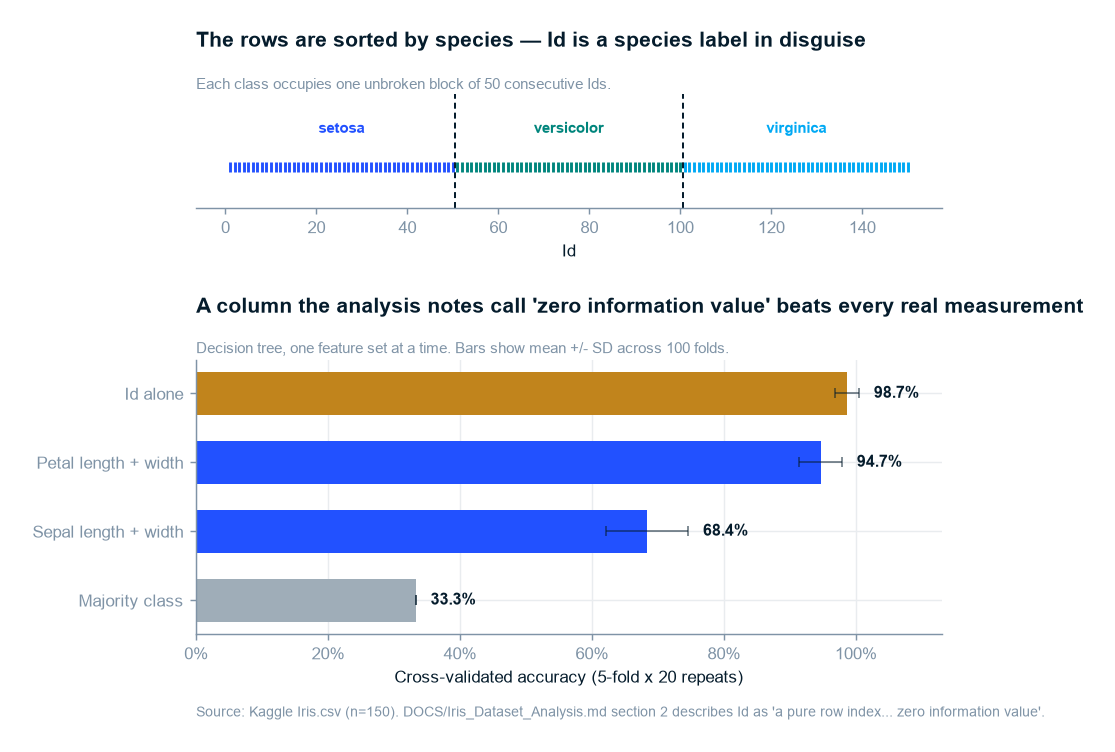

In [9]:
fig, (ax_top, ax) = plt.subplots(2, 1, figsize=(7.4, 5.4), height_ratios=[1, 2.4],
                                 gridspec_kw={"hspace": 0.78})

# --- top: the ID axis, coloured by species -------------------------------------------
for sp in SPECIES_ORDER:
    sub = df[df[TARGET].astype(str) == sp]
    ax_top.scatter(sub.Id, np.zeros(len(sub)), s=26, color=SPECIES_COLOR[sp],
                   label=SPECIES_SHORT[sp], marker="|", linewidth=1.6)
    ax_top.text(sub.Id.mean(), 0.42, SPECIES_SHORT[sp], ha="center", fontsize=8.5,
                color=SPECIES_COLOR[sp], fontweight="bold")
for b in (50.5, 100.5):
    ax_top.axvline(b, color=NAVY, lw=1.1, ls=(0, (3, 2)))
ax_top.set_ylim(-0.5, 0.9); ax_top.set_yticks([])
ax_top.set_xlabel("Id"); ax_top.grid(False)
ax_top.spines["left"].set_visible(False)
action_title(ax_top, "The rows are sorted by species — Id is a species label in disguise",
             "Each class occupies one unbroken block of 50 consecutive Ids.")

# --- bottom: what that does to a model ------------------------------------------------
order = id_leak.sort_values("cv_accuracy")
colors = [AMBER if f == "Id alone" else (GREY if f == "Majority class" else BLUE)
          for f in order.feature_set]
bars = ax.barh(order.feature_set, order.cv_accuracy, color=colors, height=.62)
ax.errorbar(order.cv_accuracy, order.feature_set, xerr=order.cv_sd, fmt="none",
            ecolor=NAVY, elinewidth=1, capsize=3, alpha=.55)
for b, v, sd in zip(bars, order.cv_accuracy, order.cv_sd):
    ax.text(v + sd + .022, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center",
            fontsize=9, color=NAVY, fontweight="bold")
ax.set_xlim(0, 1.13); ax.set_xlabel("Cross-validated accuracy (5-fold x 20 repeats)")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
action_title(ax, "A column the analysis notes call 'zero information value' beats every real measurement",
             "Decision tree, one feature set at a time. Bars show mean +/- SD across 100 folds.")
ax.text(0, -0.30, "Source: Kaggle Iris.csv (n=150). DOCS/Iris_Dataset_Analysis.md section 2 describes "
                  "Id as 'a pure row index... zero information value'.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex01_id_leakage")
plt.show()

**So What:** the leak is not subtle and not hypothetical — `Id` alone reaches 98.7%, above every
genuine feature set in the file.

**Implication:** this is the same failure mode as a production export sorted by outcome, and it
passes every completeness and range check in Stage 1. The generalisable rule for the team's
ingestion template: **any monotonic identifier must be tested against the target before it is
dismissed as an index**, because "it's just a row number" is a statement about intent, not about
information.

## 2.5 The measurement-scale contract

Persisted to `data/processed/_column_contract.csv` so every downstream notebook reads the same
decisions instead of re-making them.

| Column | Branch | Scale | Role |
|---|---|---|---|
| `SepalLengthCm`, `SepalWidthCm` | B — sepal morphology | continuous, cm, 0.1 grid | feature |
| `PetalLengthCm`, `PetalWidthCm` | C — petal morphology | continuous, cm, 0.1 grid | feature |
| `Species` | — | **nominal**, 3 classes | target |
| `Id` | A — instrument | identifier | **quarantined (leakage)** |

Two decisions worth stating explicitly rather than leaving to the default:

- **`Species` is nominal, never ordinal.** Setosa is not "less than" virginica. It is label-encoded
  for scikit-learn's convenience and never fed to a regression — `DOCS/Iris_Dataset_Analysis.md` §6
  makes the same point and it is enforced here in the contract rather than trusted to discipline.
- **Scaling is a convenience, not a rescue.** All four features are already in centimetres and span
  comparable ranges, so standardisation changes nothing about which features dominate. It is applied
  inside the modelling pipeline for the distance- and gradient-based models that require it, and it
  is stated here so no reader assumes it is doing hidden work.

In [10]:
contract = pd.DataFrame([
    {"column": "Id", "branch": "A - instrument", "scale": "identifier", "role": "quarantined",
     "note": "leakage: 98.7% CV accuracy alone; species-sorted. Never in a feature matrix."},
    {"column": "SepalLengthCm", "branch": "B - sepal", "scale": "continuous_cm_0.1grid",
     "role": "feature", "note": "35 distinct values"},
    {"column": "SepalWidthCm", "branch": "B - sepal", "scale": "continuous_cm_0.1grid",
     "role": "feature", "note": "23 distinct values"},
    {"column": "PetalLengthCm", "branch": "C - petal", "scale": "continuous_cm_0.1grid",
     "role": "feature", "note": "43 distinct values"},
    {"column": "PetalWidthCm", "branch": "C - petal", "scale": "continuous_cm_0.1grid",
     "role": "feature", "note": "22 distinct values - coarsest feature, bounds threshold resolution"},
    {"column": "Species", "branch": "-", "scale": "nominal_3class", "role": "target",
     "note": "NOT ordinal; label-encoded for sklearn only; never a regression target"},
])
contract.to_csv(PROC / "_column_contract.csv", index=False)
contract

,column,branch,scale,role,note
0,Id,A - instrument,identifier,quarantined,leakage: 98.7% CV accuracy alone; species-sort...
1,SepalLengthCm,B - sepal,continuous_cm_0.1grid,feature,35 distinct values
2,SepalWidthCm,B - sepal,continuous_cm_0.1grid,feature,23 distinct values
3,PetalLengthCm,C - petal,continuous_cm_0.1grid,feature,43 distinct values
4,PetalWidthCm,C - petal,continuous_cm_0.1grid,feature,"22 distinct values - coarsest feature, bounds ..."
5,Species,-,nominal_3class,target,NOT ordinal; label-encoded for sklearn only; n...


## 2.6 Outliers — retained, and checked for a specific thing

STRUCTURE.md §2: never remove outliers without a documented reason. There is no reason here. A
sepal width of 4.4 cm and a petal length of 1.0 cm are unremarkable botanical measurements, and the
file's whole value is that it is Anderson's actual field data.

One targeted check is run rather than a generic outlier sweep: **are the extreme specimens the same
ones models will get wrong?** If yes, the errors are a data-quality problem. If no, the errors are
genuine biological overlap — which cleaning cannot fix and no model can escape. Notebook 05
identifies the misclassified set; the outlier flags are computed here so the two can be compared.

In [11]:
z = (df[MEASUREMENTS] - df[MEASUREMENTS].mean()) / df[MEASUREMENTS].std()
q1, q3 = df[MEASUREMENTS].quantile(.25), df[MEASUREMENTS].quantile(.75)
iqr = q3 - q1
iqr_out = (df[MEASUREMENTS] < (q1 - 1.5 * iqr)) | (df[MEASUREMENTS] > (q3 + 1.5 * iqr))

# within-species outliers matter more than global ones for a 3-cluster problem
within = df.groupby(TARGET)[MEASUREMENTS].transform(lambda s: (s - s.mean()) / s.std())
flags = pd.DataFrame({
    "Id": df.Id,
    "species": df[TARGET].astype(str).map(SPECIES_SHORT),
    "global_iqr_outlier": iqr_out.any(axis=1).to_numpy(),
    "max_abs_z_global": z.abs().max(axis=1).round(2).to_numpy(),
    "max_abs_z_within_species": within.abs().max(axis=1).round(2).to_numpy(),
})
flags["within_species_outlier"] = flags.max_abs_z_within_species > 2.5
flags.to_csv(PROC / "_outlier_flags.csv", index=False)

print(f"global IQR outliers        : {int(flags.global_iqr_outlier.sum())} "
      f"(Ids: {flags.loc[flags.global_iqr_outlier, 'Id'].tolist()})")
print(f"within-species |z| > 2.5   : {int(flags.within_species_outlier.sum())} "
      f"(Ids: {flags.loc[flags.within_species_outlier, 'Id'].tolist()})")
print()
print("Nothing is removed. These flags are compared against the misclassified set in 05_modeling.")
flags.sort_values("max_abs_z_within_species", ascending=False).head(8)

global IQR outliers        : 4 (Ids: [16, 33, 34, 61])
within-species |z| > 2.5   : 10 (Ids: [16, 23, 25, 42, 44, 45, 99, 107, 118, 132])

Nothing is removed. These flags are compared against the misclassified set in 05_modeling.


,Id,species,global_iqr_outlier,max_abs_z_global,max_abs_z_within_species,within_species_outlier
43,44,setosa,False,1.22,3.32,True
41,42,setosa,False,1.74,2.93,True
98,99,versicolor,False,1.28,2.68,True
22,23,setosa,False,1.56,2.67,True
106,107,virginica,False,1.28,2.65,True
15,16,setosa,True,3.10,2.58,True
117,118,virginica,False,2.24,2.56,True
131,132,virginica,False,2.48,2.56,True


## 2.7 Feature engineering is deferred, deliberately

`DOCS/Iris_Dataset_Analysis.md` §7 proposes seven derived features (areas, length:width ratios,
petal:sepal ratios, a total-size composite). **None are created here.**

They are built inside the modelling `Pipeline` in `05_modeling.ipynb` and ablation-tested, because
a feature that is created in a cleaning notebook is a feature nobody ever removes. The notes
themselves hedge correctly — *"worth testing with/without these engineered features rather than
assuming they help"* — and this project does the test and reports the answer.

One precondition is verified now rather than discovered later: every denominator these features
need is strictly positive, so no divide-by-zero guard is required.

In [12]:
denoms = {"SepalWidthCm (sepal L:W ratio)": df.SepalWidthCm,
          "PetalWidthCm (petal L:W ratio)": df.PetalWidthCm,
          "SepalLengthCm (petal:sepal length)": df.SepalLengthCm,
          "SepalArea (petal:sepal area)": df.SepalLengthCm * df.SepalWidthCm}
for name, s in denoms.items():
    print(f"{name:38s} min = {s.min():6.2f}   zeros = {int((s == 0).sum())}")
print("\nAll denominators strictly positive - no guard needed, verified rather than assumed.")

SepalWidthCm (sepal L:W ratio)         min =   2.00   zeros = 0
PetalWidthCm (petal L:W ratio)         min =   0.10   zeros = 0
SepalLengthCm (petal:sepal length)     min =   4.30   zeros = 0
SepalArea (petal:sepal area)           min =  10.00   zeros = 0

All denominators strictly positive - no guard needed, verified rather than assumed.


## 2.8 Outputs — one primary dataset, two sensitivity variants

The primary dataset is **the file as delivered**. Duplicates stay in and the errata stay in, because
that is the file the world actually uses, and because dropping rows would break the 50/50/50 balance
this dataset is prized for.

Both defects are then carried as **persisted variants running the identical Stage 5–6 protocol**, so
their effect is measured:

| Variant | Rows | Balance | What it isolates |
|---|---|---|---|
| `iris_clean` | 150 | 50/50/50 | the file as everyone uses it — **primary** |
| `iris_dedup` | 147 | 48/50/49 | the cost of duplicate leakage across splits |
| `iris_errata_corrected` | 150 | 50/50/50 | the cost of the two transcription errors |

Note what deduplication does to the class balance: it destroys it. That is precisely why it is a
sensitivity run and not the primary — the fix has its own cost.

In [13]:
log = []

def emit(name, frame, action, rows_affected, why):
    frame = frame.set_index("Id")
    frame.to_parquet(PROC / f"{name}.parquet")
    log.append({"artefact": name, "action": action, "n_rows": len(frame),
                "rows_affected": rows_affected, "why": why})
    counts = frame[TARGET].astype(str).value_counts()
    print(f"{name:24s} {len(frame):3d} rows   balance "
          f"{'/'.join(str(counts.get(s, 0)) for s in SPECIES_ORDER)}")
    return frame

keep = ["Id"] + MEASUREMENTS + [TARGET]
emit("iris_clean", df[keep].copy(), "none - file as delivered", 0,
     "primary dataset; duplicates and errata retained so results describe the file the world uses")
emit("iris_dedup", df[keep].drop_duplicates(subset=MEASUREMENTS, keep="first").copy(),
     "drop 3 duplicate rows (keep first)", 3,
     "sensitivity: isolates duplicate leakage across train/test splits; breaks 50/50/50 balance")
emit("iris_errata_corrected", df_corrected[keep].copy(),
     "apply UCI documented corrections to Ids 35 and 38", 2,
     "sensitivity: isolates the two transcription errors; dissolves the fabricated triplicate")

cleaning_log = pd.DataFrame(log)
cleaning_log.to_csv(PROC / "_cleaning_log.csv", index=False)
print()
cleaning_log

iris_clean               150 rows   balance 50/50/50
iris_dedup               147 rows   balance 48/50/49
iris_errata_corrected    150 rows   balance 50/50/50



,artefact,action,n_rows,rows_affected,why
0,iris_clean,none - file as delivered,150,0,primary dataset; duplicates and errata retaine...
1,iris_dedup,drop 3 duplicate rows (keep first),147,3,sensitivity: isolates duplicate leakage across...
2,iris_errata_corrected,apply UCI documented corrections to Ids 35 and 38,150,2,sensitivity: isolates the two transcription er...


## Stage 2 — Gate Checklist

- [x] **Missing-value strategy documented per column** — not applicable, with reason: zero nulls
      (Stage 1, verified). Documented rather than silently skipped.
- [x] **Duplicates assessed and handled with justification** — and, more usefully, **diagnosed into
      two distinct causes**: a fabricated triplicate (`Id` 10/35/38 — transcription damage, held by
      three converging lines of evidence: the UCI errata note, the collision dissolving exactly
      under correction, and the chance-excess disappearing with it) and a genuine duplicate pair
      (`Id` 102/143 — an ordinary collision at 0.1 cm resolution). Retained in the primary set;
      both defects carried as persisted sensitivity variants.
- [x] **All columns have correct dtypes** — measurement-scale contract persisted to
      `_column_contract.csv`; `Species` fixed as nominal, `Id` quarantined as an identifier.
- [x] **Business-rule validations pass** — Stage 1, 16 of 16 rules; denominator positivity for the
      Stage 4 derived features verified here.
- [x] **Cleaning log exists** — `_cleaning_log.csv`: what changed, how many rows, and why, for all
      three artefacts.
- [x] **Cleaned data saved to `data/processed/`** — `iris_clean.parquet` (primary) plus
      `iris_dedup` and `iris_errata_corrected` variants.
- [x] **Outliers retained**, with a documented reason and a targeted flag file for comparison
      against the misclassified set in Stage 6.

**Key Line 1 is now evidenced:** an identifier that predicts the label at 98.7%, two transcription
errors that fabricate a specimen, and a duplicate pair that two-thirds of random splits leak across
the train/test boundary — none of which any completeness check can see.

**Next:** `03_eda.ipynb` — where the signal actually lives.